# The 160m non-adaptive strip: where (and when) subliminal transfer peaks

The companion to `pythia410m_collapse_and_peak.ipynb` §4–§5, run on the **160m non-adaptive
8×7 strip** (**cross-init**: the original-init `pythia-160m` focus teacher `ep2_lr5e-4_r32a64`
→ `pythia-160m-data-seed1` students — the orig→ds1 lineage, not ds1 same-model; ep20, the full factorial r ∈ {1…128} × α ∈ {4…256} × a shared 9-rung lr ladder
5e-6…2e-3 × 2 ftseeds = 1008 runs; design/census/law in `nors_asks.ipynb` §7, harvest
`analysis/nonadaptive_8x7_harvest.json`). 932 of those runs carry the 40-checkpoint
`eval/pref_traj.json` + `eval/pile_kl_traj.json` trajectories.

What exists already: `ckpt_trajectories.ipynb` §2 shows the **dose** (‖ΔW‖) is monotone in
training, and §6 shows alive runs' trait plateaus at ~70% of training with "no alive run
overshooting its own endpoint". What was *not* done on 160m is the apparatus the 410m notebook
needed: the house $K/K^\ast$ × α × rank grids for **ep20 endpoint vs best checkpoint**, the
per-run peak-step / overshoot statistics against dose, and a side-by-side with 410m. At 410m
those showed rise-then-decay (median peak at 20% of training, best checkpoint ≫ endpoint). This
notebook asks whether 160m really is different, on the same footing.

Conventions as everywhere: $K=\mathrm{lr}\,\alpha^{0.561}r^{-0.085}$, display unit
$K^\ast_{160m}=$ `cl.KSTAR_CALIBRATED`; transfer = test $p(\text{dog})$ / the receiver's own
test prior; dead = endpoint pp1 Pile-KL $>$ `DEAD_KL_CUT` (the only collapse label; test $p$ is a
continuous readout). Row unit is one run (cell × ftseed) unless a table says otherwise.

## 0. Setup

In [1]:
from __future__ import annotations

import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_json
from subliminal_learning.analysis.probe_cache import load_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()
AN = OUTPUT_ROOT / "analysis"

ANIMAL, TEACHER, DATASET = "dog", "ep2_lr5e-4_r32a64", "ex10-20_prefix_n100k"
KSTAR_160 = cl.KSTAR_CALIBRATED
B, Cc = cl.B_LAW, cl.C_LAW
P_VMAX = 0.2                      # house colour scale for mean test p

ARMS = {"160m strip (ds1)": ("pythia-160m-data-seed1", "pythia-160m"),
        "410m same-model":  ("pythia-410m", "pythia-410m")}
ARM_COLORS = {"160m strip (ds1)": "#74b816", "410m same-model": "#d9480f"}


def lineage_dir(student_base: str, teacher_base: str) -> Path:
    return (OUTPUT_ROOT / "students" / ANIMAL / student_base / f"teacher-{teacher_base}"
            / f"{TEACHER}_tseed1" / DATASET)


def traj_stats(leaf: Path) -> dict:
    f, g = leaf / "eval" / "pref_traj.json", leaf / "eval" / "pile_kl_traj.json"
    if not f.exists():
        return {}
    pts = [p for p in read_json(f)["points"] if p.get("step") is not None and "test" in p]
    if len(pts) < 20:
        return {}
    # two schemas: 410m writes test={p_target,...}; the 160m strip writes test={animal: {p_target,...}}
    def _p(pt):
        t = pt["test"]
        return t["p_target"] if "p_target" in t else t[ANIMAL]["p_target"]
    # the strip's final row (checkpoint "checkpoints" = the endpoint adapter) is kept: it is the run's last point
    steps = np.array([p["step"] for p in pts], float); tp = np.array([_p(p) for p in pts], float)
    i = int(np.nanargmax(tp))
    out = {"n_ckpt": len(pts), "peak_step_frac": steps[i] / steps.max(), "best_test": tp[i], "end_traj_test": tp[-1],
           "overshoot": tp[i] / max(tp[-1], 1e-9),
           "plateau_test": float(np.median(tp[-8:])), "t_half_frac": float(steps[np.argmax(tp >= 0.5 * tp[i])] / steps.max())}
    if g.exists():
        kp = [p for p in read_json(g)["points"] if p.get("step") is not None]
        kl = np.array([p["kl_base_adapted"] for p in kp], float); ks = np.array([p["step"] for p in kp], float)
        if len(kl):
            out["kl_at_peak"] = float(np.interp(steps[i], ks, kl))
    return out


print(f"K*_160m = {KSTAR_160:.3g}  b={B} c={Cc}  DEAD_KL_CUT={DEAD_KL_CUT}")

K*_160m = 0.00084  b=0.561 c=-0.085  DEAD_KL_CUT=4.0


## 1. Populations + inventory

**160m strip**: the 1008-run harvest is the population (tag, seed, endpoint `test_p`,
`diverged`); Pile-KL comes from the shared `pile_probe` record cache, trajectories from each
run dir. Prior = `analysis/base_eval_ds1_animal_preference_test.json` mean over the 50 test
prompts. **410m same-model**: read straight off its run dirs as in the 410m notebook (a draining
snapshot; prior from `base_control.json`). Counts below: runs, runs with an endpoint, runs with a
KL record, runs with a trajectory.

In [2]:
# ---- 160m strip
harv = pd.read_json(AN / "nonadaptive_8x7_harvest.json")
harv = harv.rename(columns={"tag": "student_tag", "test_p": "test"})
ld160 = lineage_dir(*ARMS["160m strip (ds1)"])
harv["leaf"] = [str(ld160 / t / f"ftseed{s}") for t, s in zip(harv.student_tag, harv.seed)]
pc = load_probe_cache(OUTPUT_ROOT, [str(Path(p).relative_to(OUTPUT_ROOT)) for p in harv.leaf], refresh=True, pool_version="pp1")
pc = pc.assign(leaf=[str(OUTPUT_ROOT / p) for p in pc.run_path])[["leaf", "kl"]]
s160 = harv.merge(pc, on="leaf", how="left")
s160.loc[s160.diverged, ["test", "kl"]] = [0.0, math.inf]
s160["test_prior"] = float(np.mean(read_json(AN / "base_eval_ds1_animal_preference_test.json")[ANIMAL]["p_per_prompt"]))
s160["arm"] = "160m strip (ds1)"

# ---- 410m same-model (run dirs)
ld410 = lineage_dir(*ARMS["410m same-model"])
rows = []
for cell in sorted(ld410.glob("ep20_*")):
    pt = parse_param_tag(cell.name)
    for leaf in sorted(cell.glob("ftseed*")):
        rec = dict(student_tag=cell.name, seed=int(leaf.name.removeprefix("ftseed")), lr=pt["lr"], alpha=pt["alpha"],
                   rank=pt["rank"], leaf=str(leaf), diverged=(leaf / "train_diverged.json").exists())
        pe, pp = leaf / "preference_eval.json", leaf / "eval" / "pile_probe.json"
        if rec["diverged"]:
            rec.update(test=0.0, kl=math.inf)
        elif pe.exists() and pp.exists():
            kl = read_json(pp).get("kl_base_student")
            rec.update(test=float(read_json(pe)["sets"]["test"]["p_target"]), kl=math.inf if kl is None else float(kl))
        else:
            rec.update(test=np.nan, kl=np.nan)
        rows.append(rec)
s410 = pd.DataFrame(rows)
s410["test_prior"] = float(read_json(ld410 / "base_control.json")["test"]["p_target"])
s410["arm"] = "410m same-model"

runs = pd.concat([s160, s410], ignore_index=True)
runs["K"] = cl.K_of(runs.lr, runs.alpha, runs["rank"]); runs["K_rel"] = runs.K / KSTAR_160
runs["s"] = runs.alpha / runs["rank"]
runs["transfer"] = runs.test / runs.test_prior
runs["dead_kl"] = runs.kl > DEAD_KL_CUT
ts = pd.DataFrame([traj_stats(Path(l)) for l in runs.leaf], index=runs.index)
runs = runs.join(ts)
runs["best_transfer"] = runs.best_test / runs.test_prior

import datetime as _dt
print("snapshot:", _dt.datetime.now().strftime("%Y-%m-%d %H:%M"))
inv = runs.groupby("arm").agg(prior=("test_prior", "first"), cells=("student_tag", "nunique"), runs=("leaf", "size"),
                              with_endpoint=("test", lambda v: int(v.notna().sum())), diverged=("diverged", "sum"),
                              with_kl=("kl", lambda v: int(v.notna().sum())),
                              with_traj=("peak_step_frac", lambda v: int(v.notna().sum())),
                              ftseeds=("seed", "nunique"), K_rel_min=("K_rel", "min"), K_rel_max=("K_rel", "max"))
display(inv.round(4))
runs = runs[runs.test.notna()].copy()

pile_probe cache: 1008 rows of 29680 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


snapshot: 2026-08-23 02:36


,prior,cells,runs,with_endpoint,diverged,with_kl,with_traj,ftseeds,K_rel_min,K_rel_max
arm,,,,,,,,,,
160m strip (ds1),0.0133,504,1008,1008,76,1008,932,2,0.0086,53.4285
410m same-model,0.0229,326,326,326,0,326,326,1,0.0205,2.4548


## 2. House grids — ep20 endpoint vs best checkpoint (160m strip)

`aplots.facet_grid_heatmaps` exactly as in `collapse_campaigns_k_alpha_rank.ipynb`: row =
$K/K^\ast_{160m}$ bin (0.05 wide from 0; the strip runs to $K/K^\ast\approx18$, so bins above
1.5 are pooled into one top row labelled `>1.50`), col = α, panel = rank; value = **mean test
$p(\text{dog})$ over the runs in the square** (2 ftseeds per cell; n = runs), house `P_VMAX`
= 0.2 on both figures. Dashed rule = $K/K^\ast_{160m}=1$. Diverged runs count as $p=0$
(they are dead on every label). First figure: ep20 endpoint. Second: best checkpoint of each
run (runs without a trajectory are omitted from the second figure — n shows it).

160m strip integrity K* (this population, logistic) = 0.000712 = 0.85 x display unit


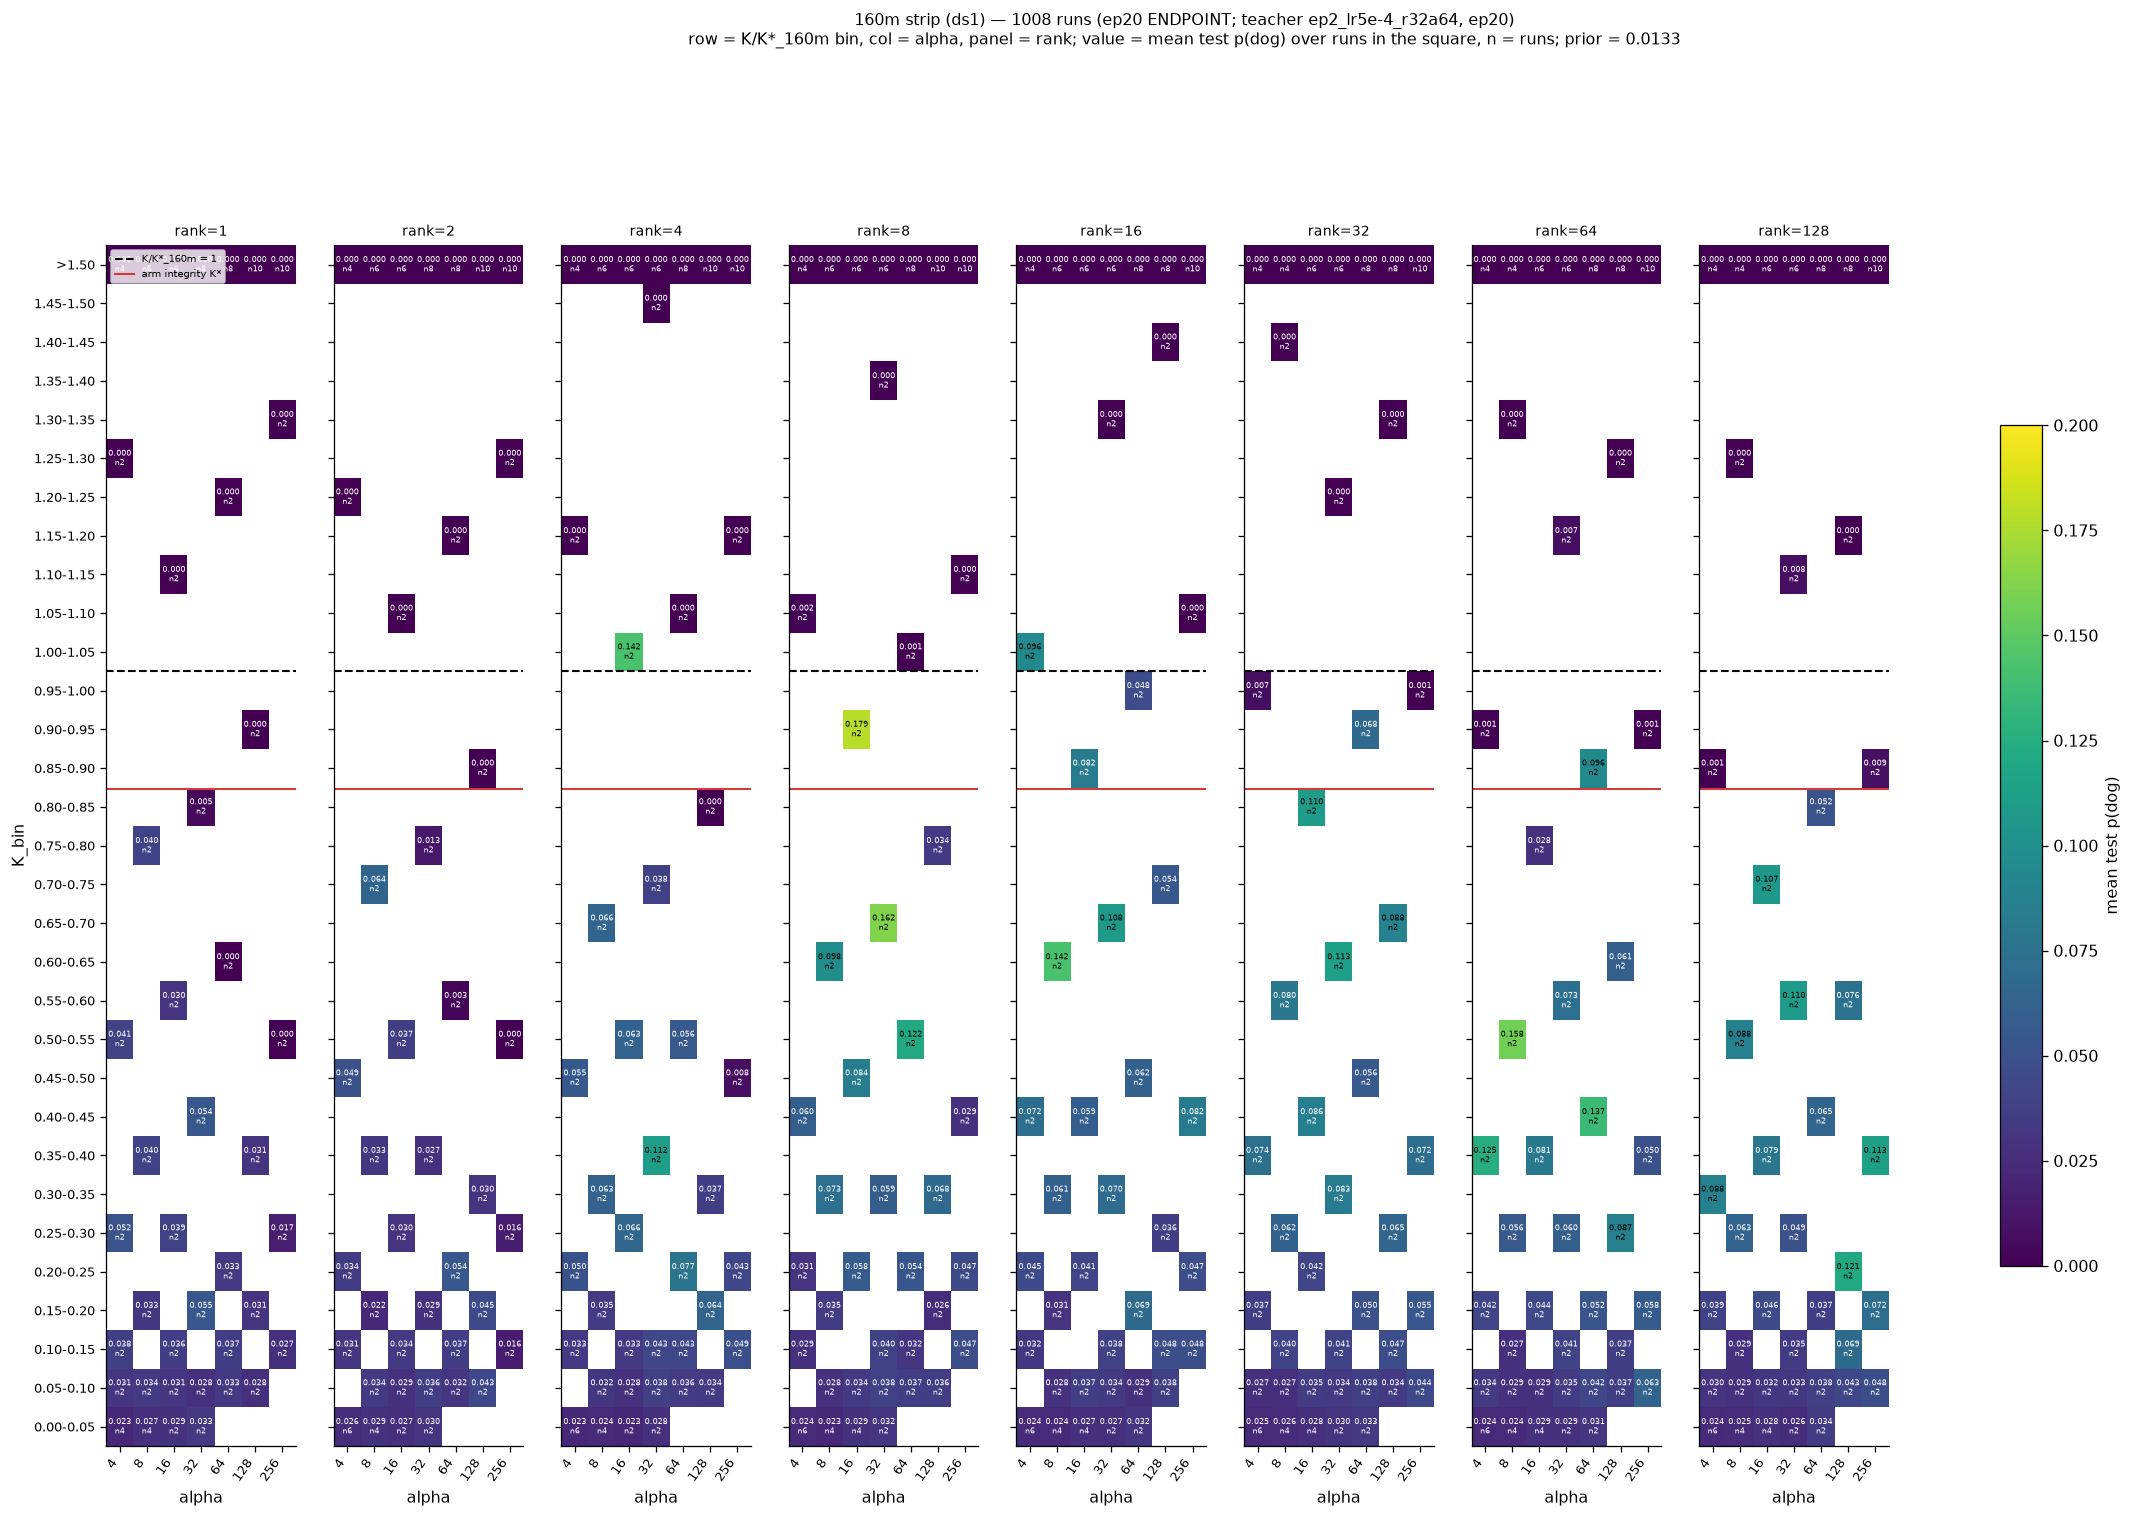

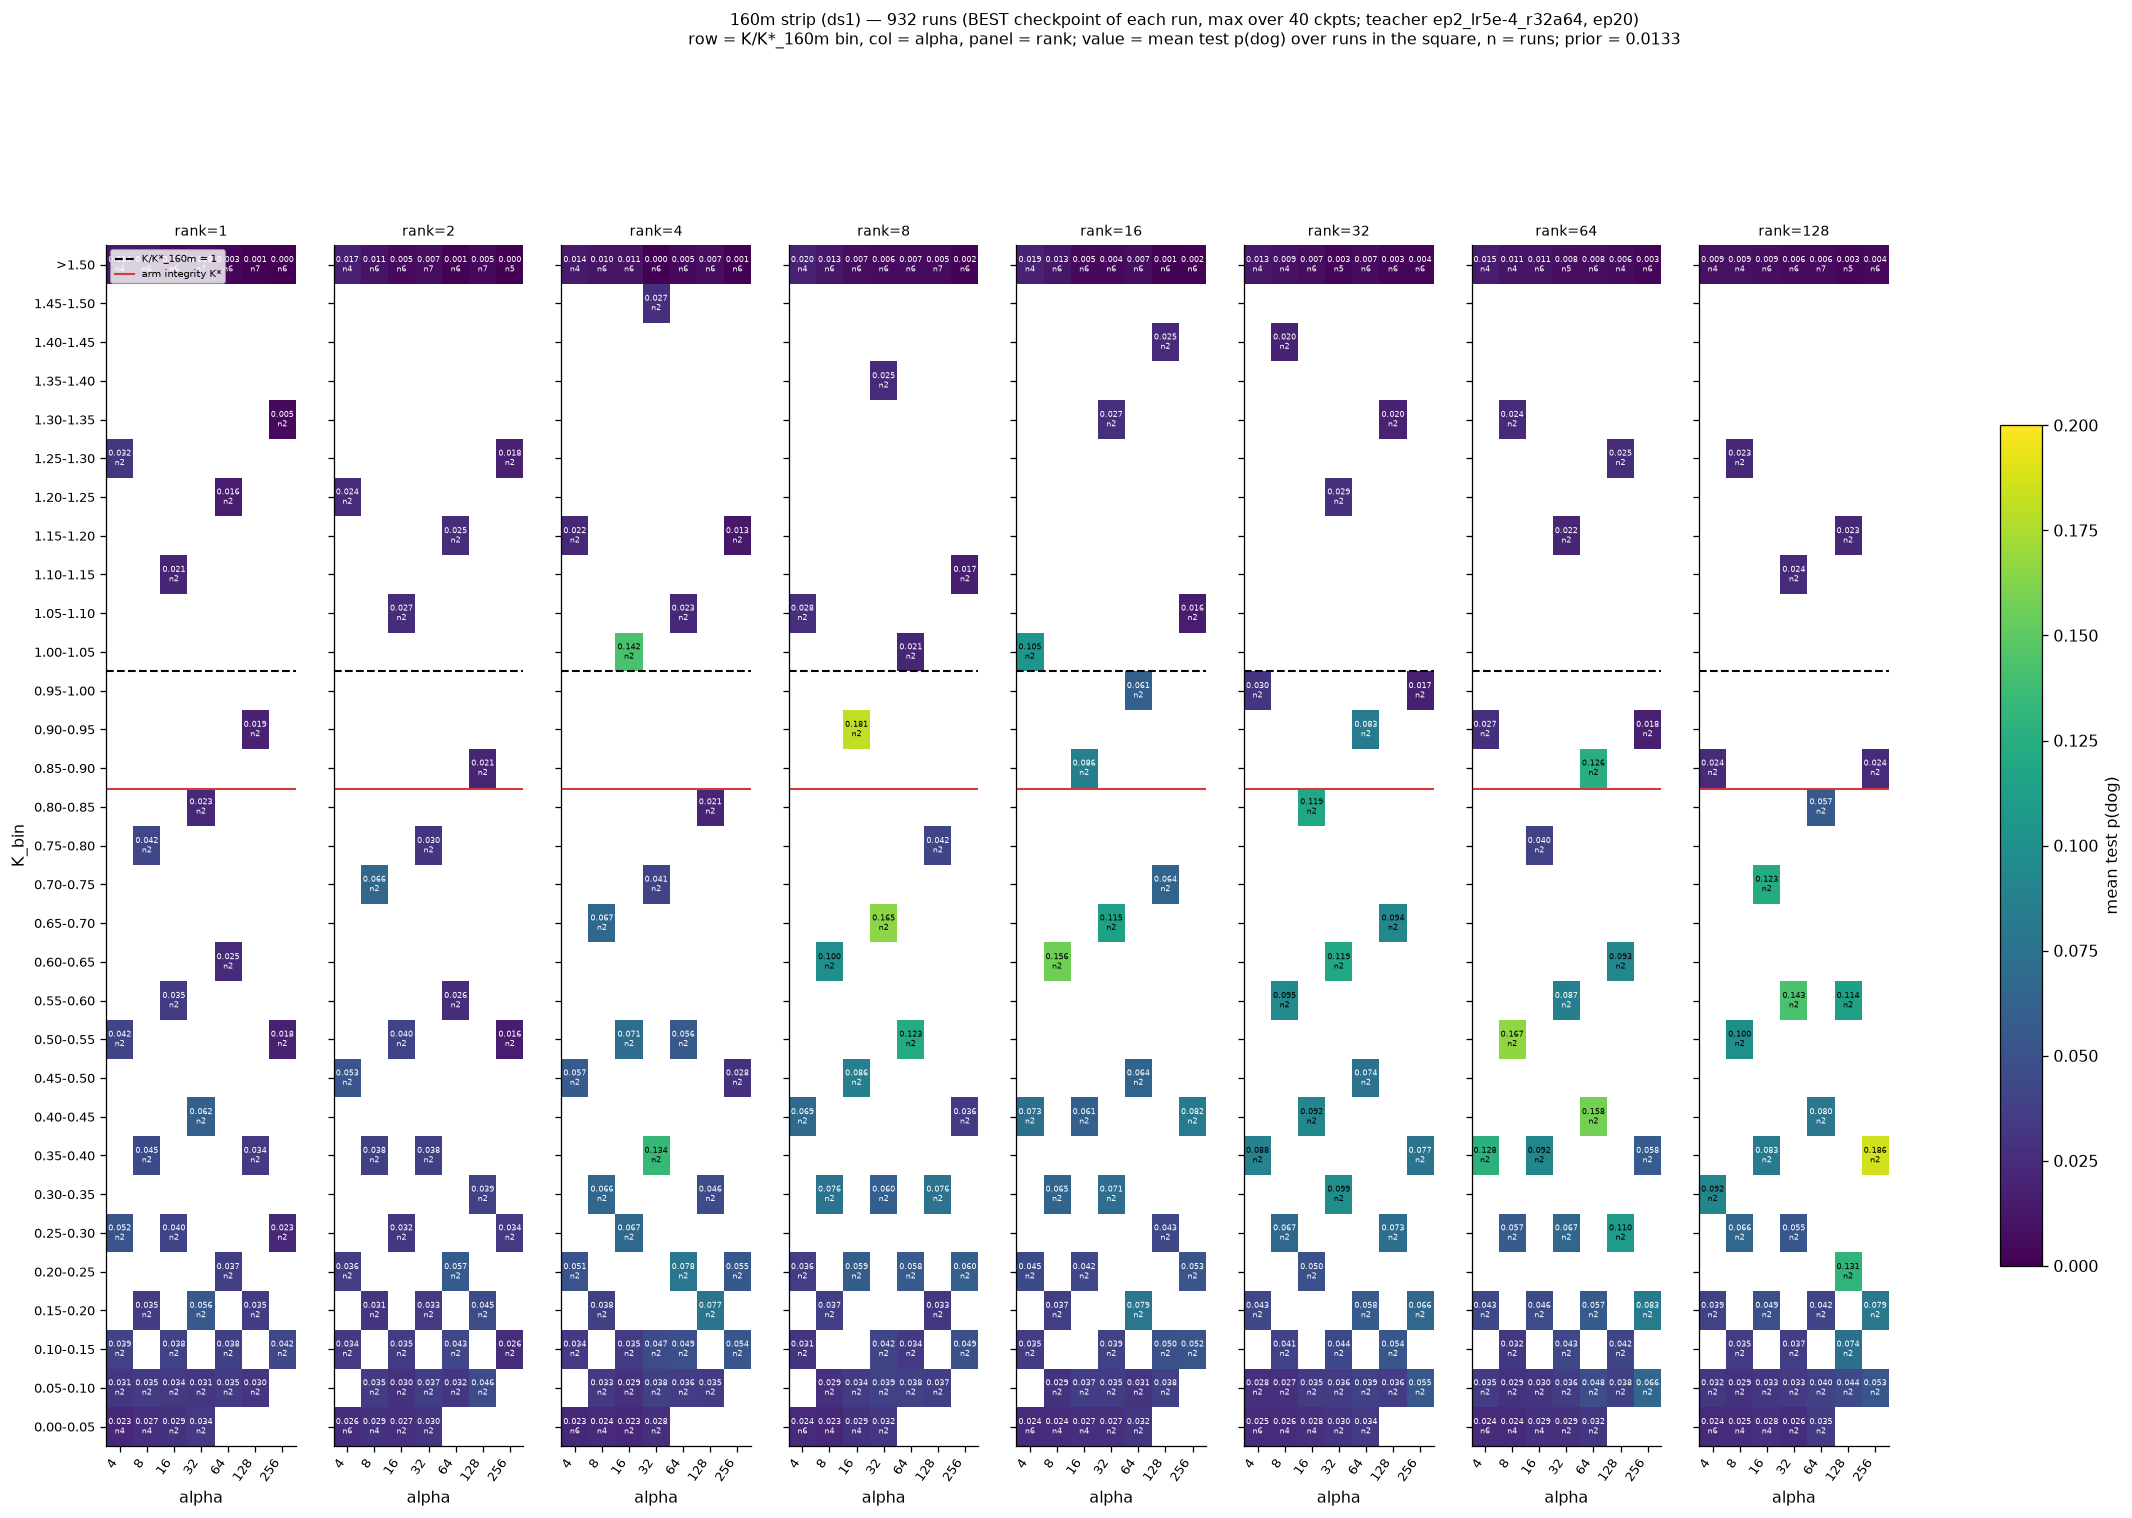

In [3]:
BIN_W = 0.05
EDGES_H = np.round(np.arange(0.0, 1.50 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.2f}-{lo + BIN_W:.2f}" for lo in EDGES_H[:-1]] + [">1.50"]


def k_bin(k_rel):
    v = np.asarray(k_rel, float)
    lab = pd.cut(pd.Series(np.clip(v, 0, 1.4999)), bins=EDGES_H, labels=BIN_LABELS[:-1], right=False,
                 include_lowest=True).astype(str).values
    lab = np.where(v >= 1.5, ">1.50", lab)
    return lab


def house_grid(sub: pd.DataFrame, arm: str, val: str, what: str, kstar_arm: float | None = None):
    sub = sub.assign(K_bin=k_bin(sub.K_rel)).dropna(subset=[val])
    k_order = [b for b in BIN_LABELS if b in set(sub.K_bin)]
    orders = {"K_bin": k_order, "alpha": sorted(sub.alpha.unique()), "rank": sorted(sub["rank"].unique())}
    boundary_row = next((i for i, b in enumerate(k_order) if b == ">1.50" or float(b.split("-")[0]) >= 1.0), len(k_order))
    fig = aplots.facet_grid_heatmaps(
        sub, row="K_bin", col="alpha", val=val, col_facet="rank", agg="mean",
        orders=orders, show_n=True, vmin=0.0, vmax=P_VMAX, cmap="viridis", fmt="{:.3f}",
        panel_w=3.0, row_h=0.36, cell_fontsize=4.8,
        title=(f"{arm} — {len(sub)} runs ({what}; teacher {TEACHER}, ep20)\n"
               "row = K/K*_160m bin, col = alpha, panel = rank; value = mean test p(dog) over runs in the square, n = runs; "
               f"prior = {sub.test_prior.iloc[0]:.4f}"),
        cbar_label="mean test p(dog)")
    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(orders["rank"]):
            ax.set_yticklabels([])
        ax.axhline(boundary_row - 0.5, color="k", ls="--", lw=1.3, label="K/K*_160m = 1" if i == 0 else None)
        if kstar_arm is not None:
            kr = kstar_arm / KSTAR_160
            for j, bl in enumerate(k_order):
                if bl != ">1.50" and float(bl.split("-")[0]) <= kr < float(bl.split("-")[0]) + BIN_W:
                    ax.axhline(j + (kr - float(bl.split("-")[0])) / BIN_W - 0.5, color="#d03b3b", lw=1.3,
                               label="arm integrity K*" if i == 0 else None)
    fig.axes[0].legend(loc="upper left", fontsize=6, frameon=True)
    plt.show()


s160r = runs[runs.arm == "160m strip (ds1)"]
f160 = s160r.assign(collapsed=s160r.dead_kl.astype(int)).dropna(subset=["kl"])
KSTAR_ARM160 = cl.kstar_logistic(f160, B, Cc)["kstar"]
print(f"160m strip integrity K* (this population, logistic) = {KSTAR_ARM160:.3g} = {KSTAR_ARM160 / KSTAR_160:.2f} x display unit")
house_grid(s160r, "160m strip (ds1)", "test", "ep20 ENDPOINT", KSTAR_ARM160)
house_grid(s160r, "160m strip (ds1)", "best_test", "BEST checkpoint of each run, max over 40 ckpts", KSTAR_ARM160)

### 2b. The same two views for the 410m same-model arm (for the eye; numbers in §5)

Same grids, same colour scale, so the two widths can be read side by side. The 410m arm is a
draining snapshot (blank squares = not landed yet).

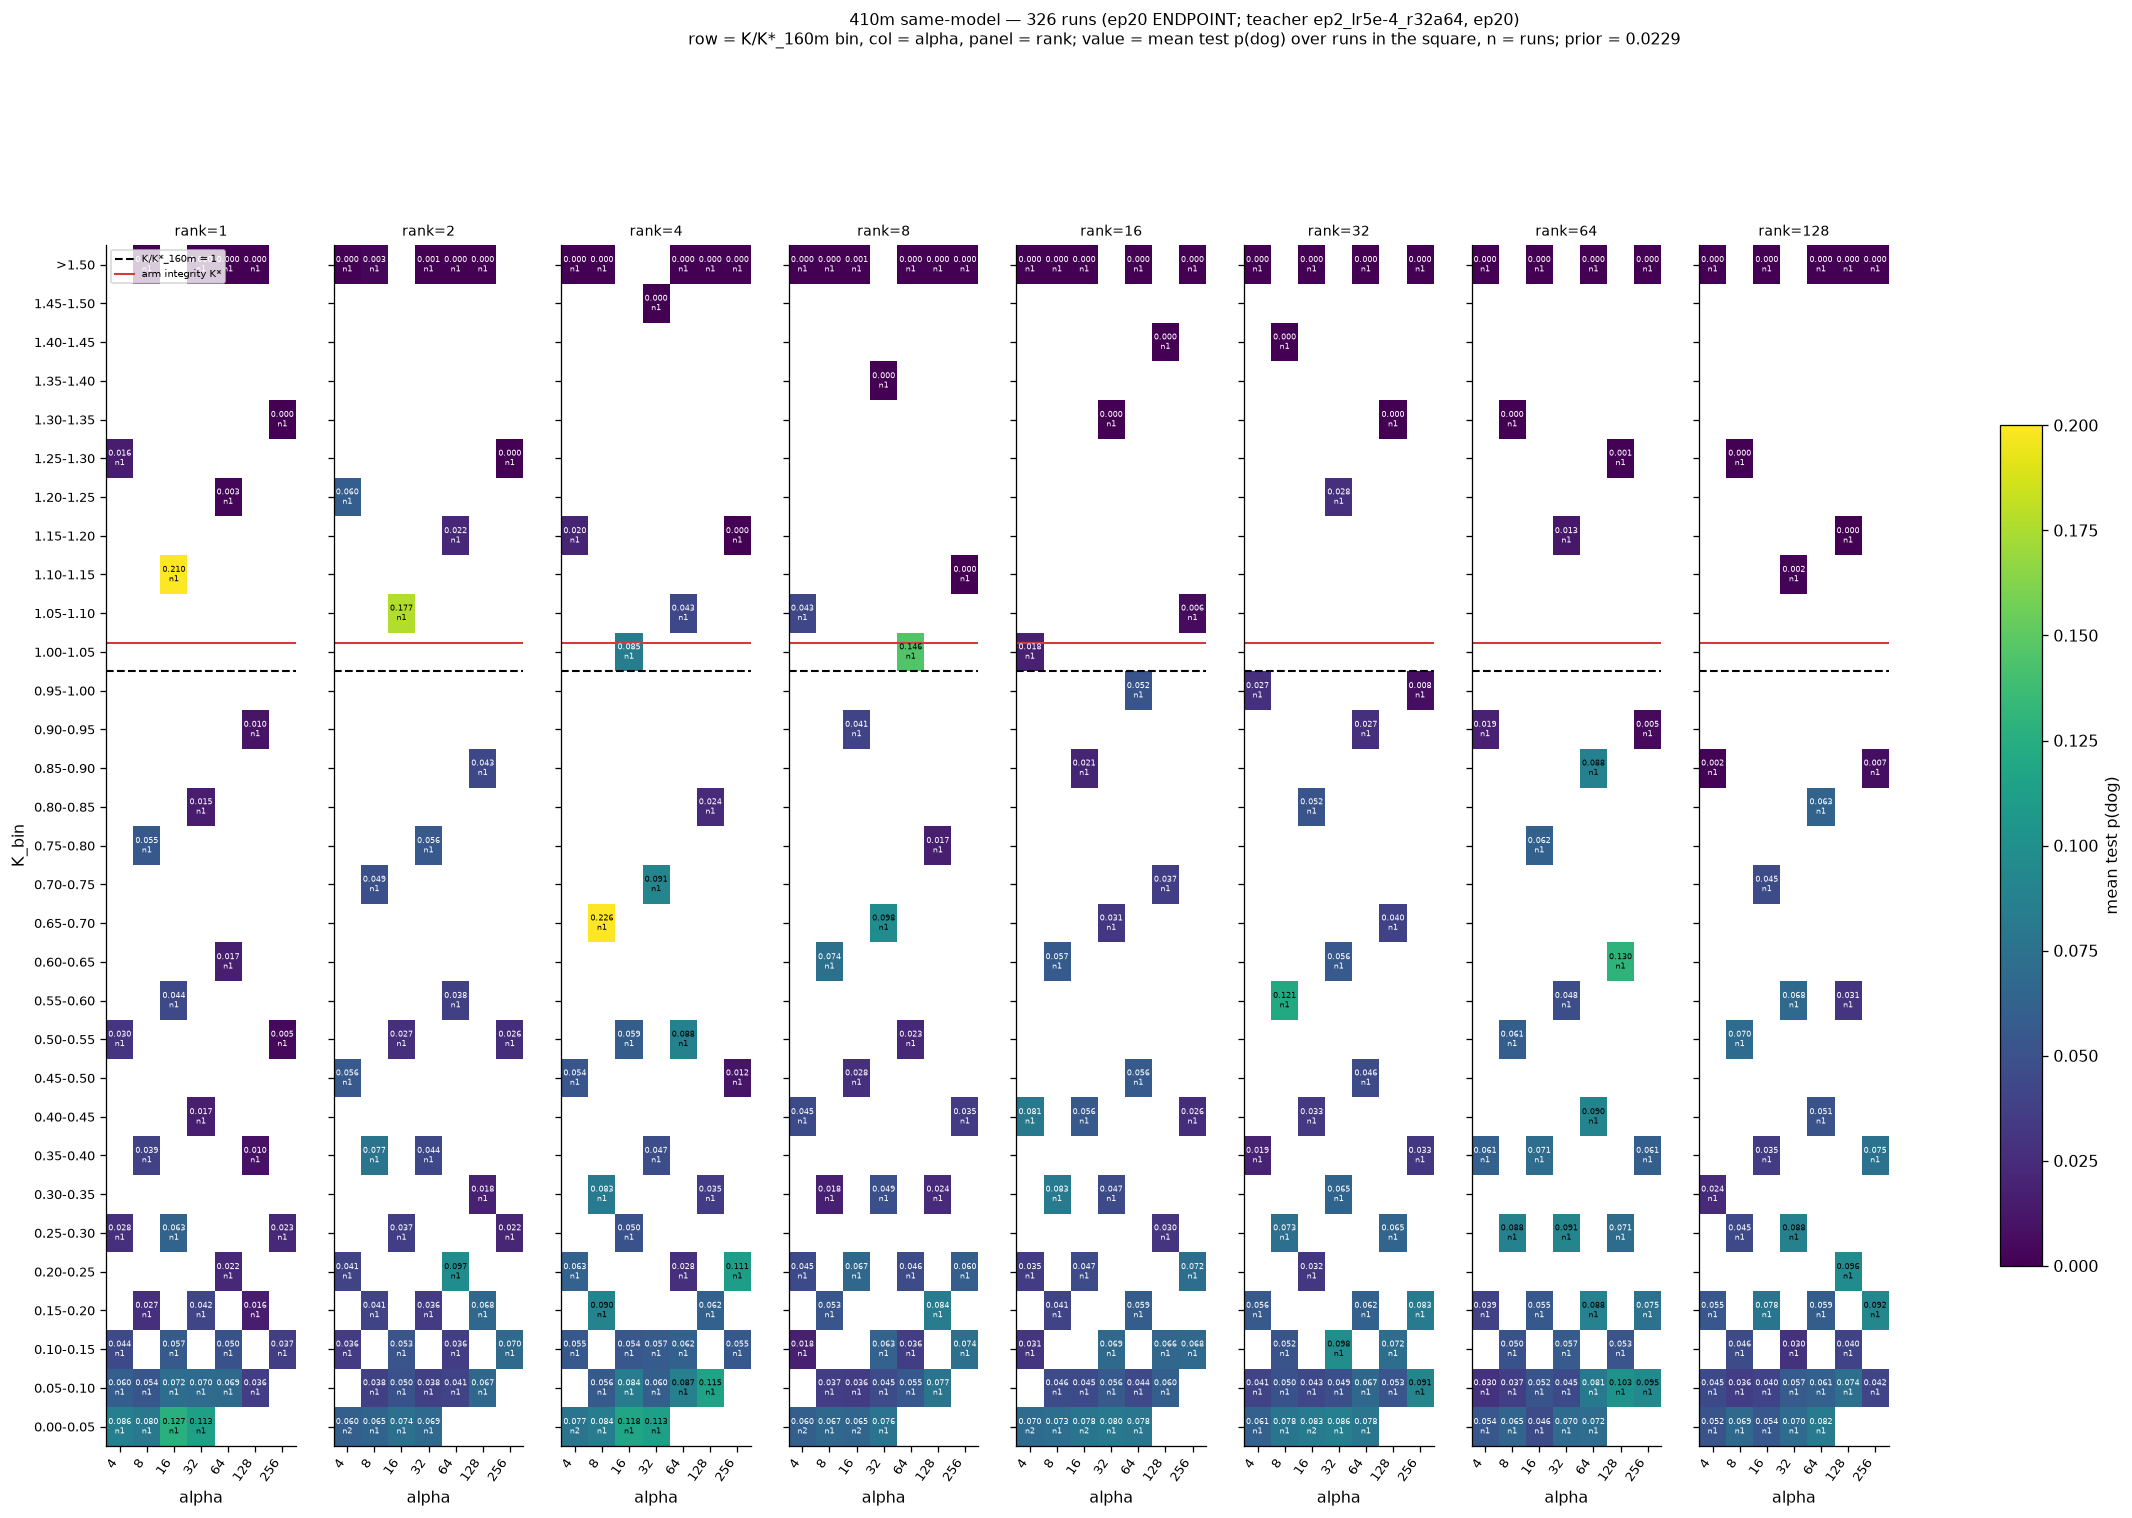

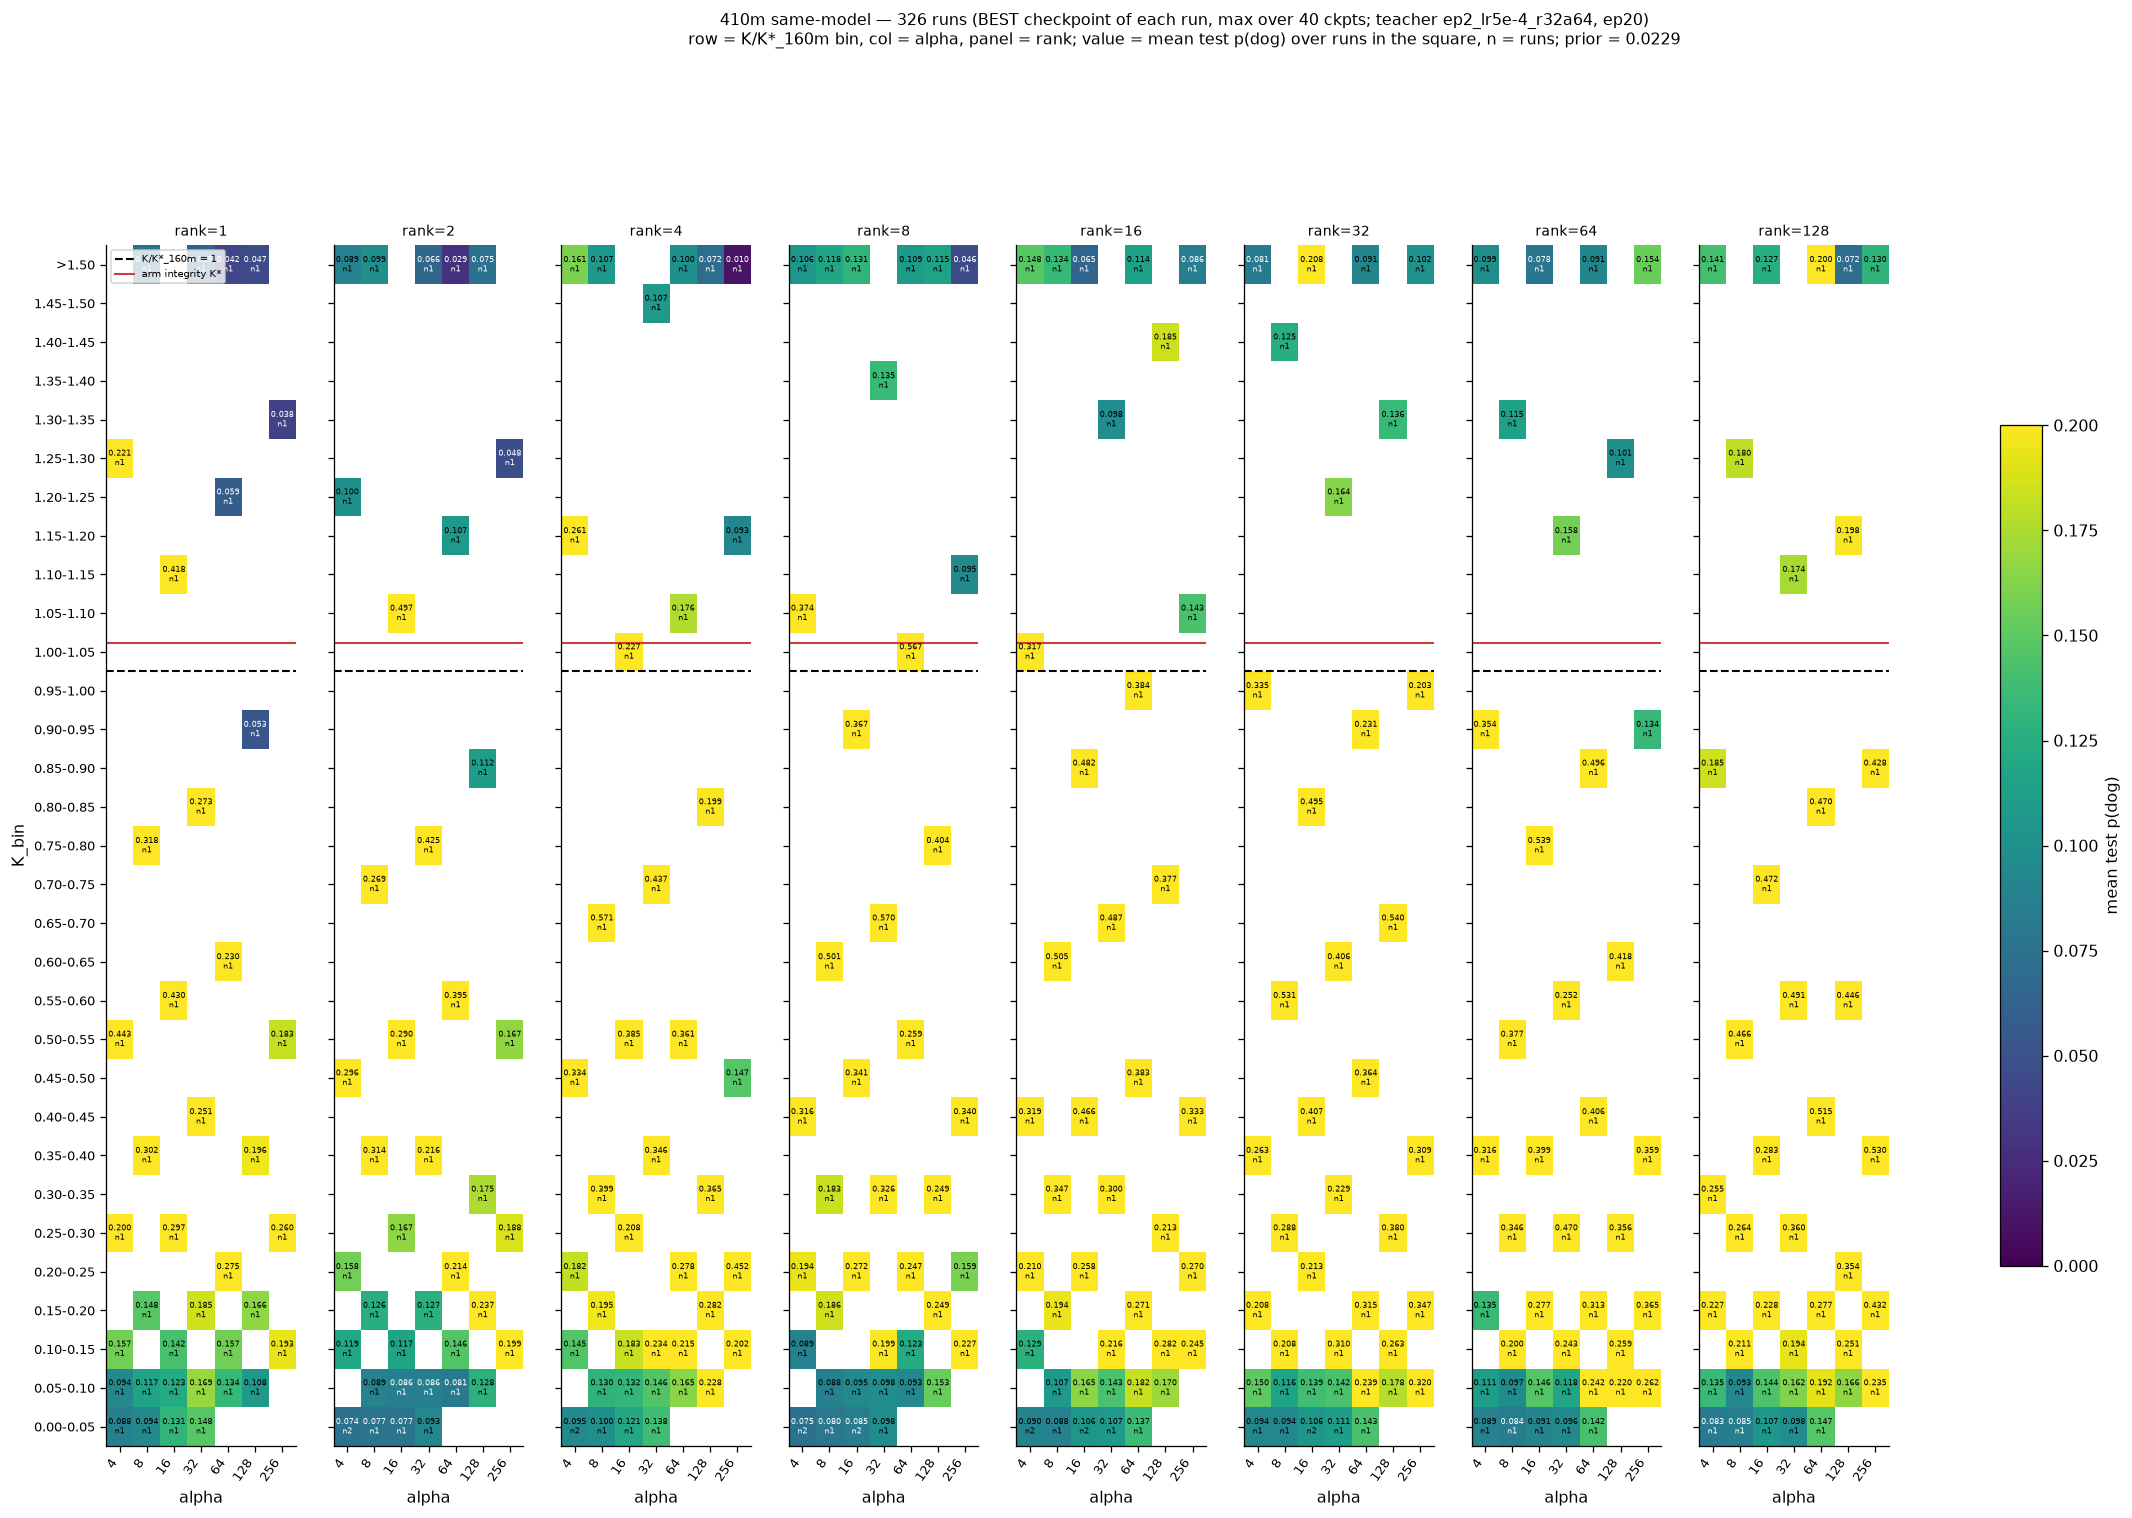

In [4]:
s410r = runs[runs.arm == "410m same-model"]
f410 = s410r.assign(collapsed=s410r.dead_kl.astype(int)).dropna(subset=["kl"])
KSTAR_ARM410 = cl.kstar_logistic(f410, B, Cc)["kstar"] if f410.collapsed.nunique() == 2 else None
house_grid(s410r, "410m same-model", "test", "ep20 ENDPOINT", KSTAR_ARM410)
house_grid(s410r, "410m same-model", "best_test", "BEST checkpoint of each run, max over 40 ckpts", KSTAR_ARM410)

## 3. Dose-response: endpoint vs best checkpoint

Transfer (test $p$ / prior) against $K/K^\ast_{160m}$, 0.2-dex bins, median + IQR. Solid =
ep20 endpoint, dashed = best checkpoint of each run. Row unit: one run. The table gives the
argmax cell and the top-decile centre of mass for each (arm × view).

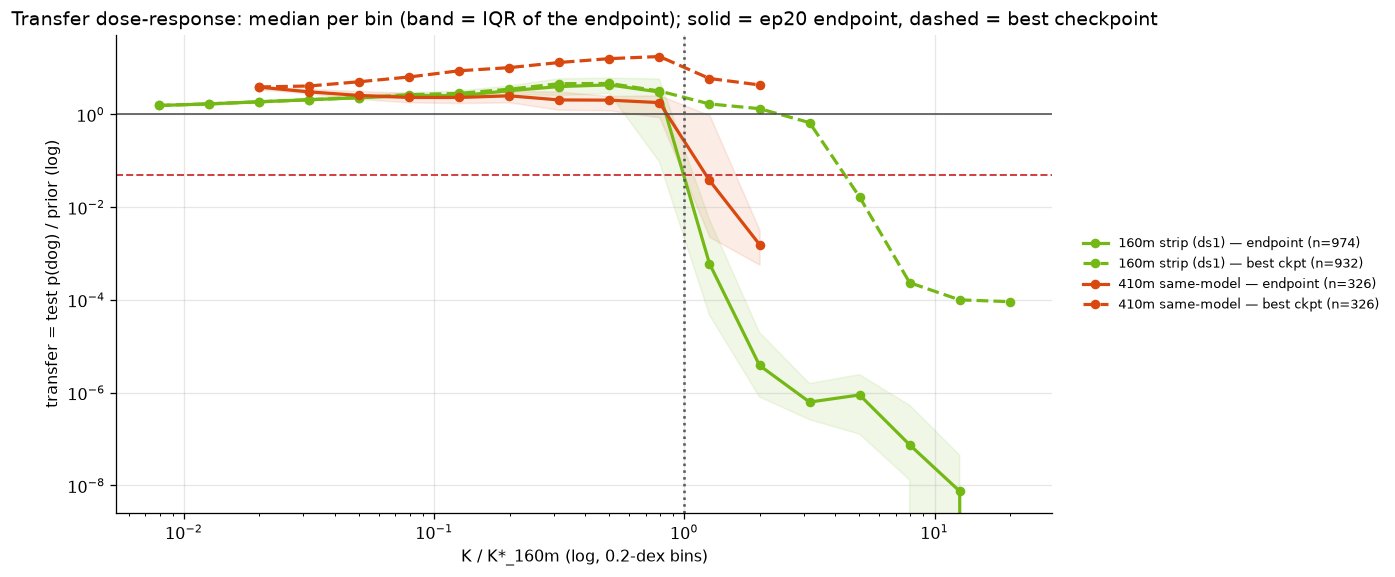

n           argmax_cell argmax_transfer argmax_K_rel top_decile_median top_decile_K_rel_geomean top_decile_K_rel_IQR
160m strip (ds1) endpoint   1008  ep20_lr2e-4_r4a16 s1       18.759498     1.002506          6.481845                 0.394063       (0.281, 0.588)
                 best ckpt   932  ep20_lr2e-4_r4a16 s1       18.759498     1.002506          7.522213                  0.42172        (0.31, 0.599)
410m same-model  endpoint    326   ep20_lr2e-4_r4a8 s1        9.869413     0.679531          4.215465                 0.184478       (0.076, 0.586)
                 best ckpt   326   ep20_lr2e-4_r4a8 s1       24.894539     0.679531         20.788106                 0.602927       (0.515, 0.797)

In [5]:
EDGES = np.arange(-2.4, 1.41, 0.2)
runs["kmid"] = pd.cut(np.log10(runs.K_rel), bins=EDGES).map(lambda b: 10 ** b.mid if pd.notna(b) else np.nan).astype(float)

fig, ax = plt.subplots(figsize=(10.5, 5.4))
for arm in ARMS:
    sub = runs[runs.arm == arm]
    for col, ls, lab in (("transfer", "-", "endpoint"), ("best_transfer", "--", "best ckpt")):
        g = sub.dropna(subset=[col]).groupby("kmid").get_group if False else sub.dropna(subset=[col]).groupby("kmid")[col]
        med, lo, hi = g.median(), g.quantile(.25), g.quantile(.75)
        ax.plot(med.index, med.values, ls, marker="o", color=ARM_COLORS[arm], lw=2, ms=5, label=f"{arm} — {lab} (n={int(g.size().sum())})")
        if col == "transfer":
            ax.fill_between(med.index, lo.values, hi.values, color=ARM_COLORS[arm], alpha=0.10)
ax.axhline(1, color="0.3", lw=1); ax.axhline(np.exp(-3), color="#d03b3b", ls="--", lw=1.2); ax.axvline(1, color="0.35", ls=":", lw=1.6)
ax.set(xscale="log", yscale="log", xlabel="K / K*_160m (log, 0.2-dex bins)", ylabel="transfer = test p(dog) / prior (log)",
       title="Transfer dose-response: median per bin (band = IQR of the endpoint); solid = ep20 endpoint, dashed = best checkpoint")
aplots.right_legend(ax, fontsize=8)
plt.show()


def peak_summary(sub: pd.DataFrame, col: str) -> dict:
    s = sub.dropna(subset=[col]).sort_values(col, ascending=False)
    top = s.head(max(3, len(s) // 10))
    return {"n": len(s), "argmax_cell": f"{s.iloc[0].student_tag} s{int(s.iloc[0].seed)}", "argmax_transfer": s.iloc[0][col],
            "argmax_K_rel": s.iloc[0].K_rel, "top_decile_median": top[col].median(),
            "top_decile_K_rel_geomean": float(np.exp(np.log(top.K_rel).mean())),
            "top_decile_K_rel_IQR": (round(top.K_rel.quantile(.25), 3), round(top.K_rel.quantile(.75), 3))}


peaks = pd.DataFrame({(a, v): peak_summary(runs[runs.arm == a], c) for a in ARMS for v, c in (("endpoint", "transfer"), ("best ckpt", "best_transfer"))}).T
display(peaks)

## 4. When the trait peaks within a run

Per run: the step fraction of the maximal test $p$ over the 40 checkpoints, the **overshoot**
= peak / endpoint, and the Pile-KL at the peak checkpoint. Left: peak-step fraction vs dose.
Middle: overshoot vs dose (1 = the endpoint *is* the peak). Right: fraction of runs with
overshoot > 2 per dose band. Alive and dead runs are both shown (dead runs trivially overshoot
— their endpoint is ~0 — so the band table also reports the alive-only numbers).

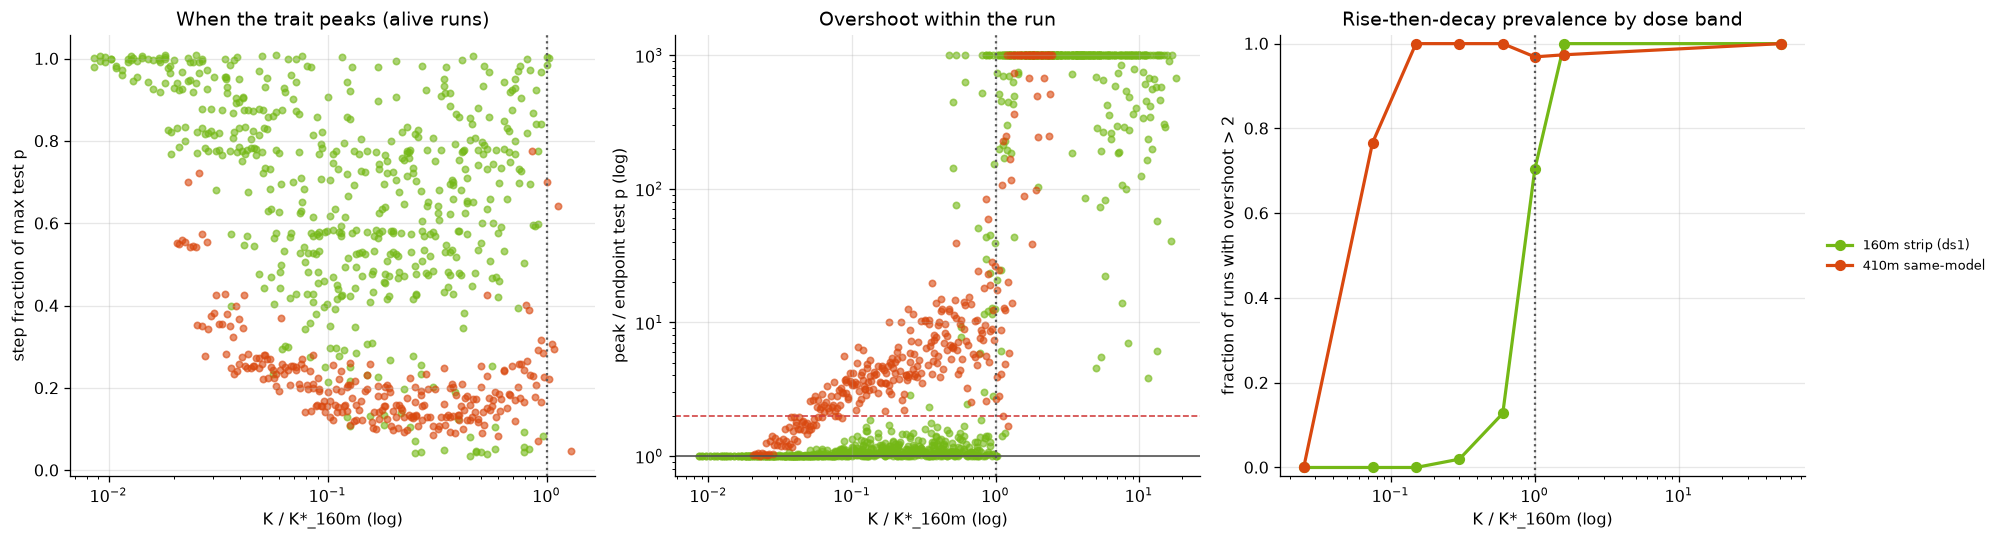

Row unit: one run with a trajectory. 'alive_*' columns restrict to integrity-alive runs (endpoint Pile-KL <= cut).


n  n_alive  peak_step_frac_med  overshoot_med  frac_overshoot_gt2  alive_overshoot_med  alive_frac_gt2  end_transfer_med  best_transfer_med  kl_at_peak_med
arm              kband                                                                                                                                                                      
160m strip (ds1) (0.0, 0.05]   128      128               0.925          1.000               0.000                1.000           0.000             1.961              1.964           0.102
                 (0.05, 0.1]    94       94               0.625          1.019               0.000                1.019           0.000             2.501              2.551           0.224
                 (0.1, 0.2]    106      106               0.575          1.066               0.000                1.066           0.000             2.802              3.073           0.338
                 (0.2, 0.4]    102      102               0.600          1.071               0.020                1.071           0.020             3.642              4.299           0.550
                 (0.4, 0.8]     94       87               0.688          1.078               0.128                1.068           0.057             4.309              4.677           0.847
                 (0.8, 1.2]     64       18               0.025         41.347               0.703                1.052           0.111             0.046              1.774           0.593
                 (1.2, 2.0]     76        0               0.025      56361.845               1.000                  NaN             NaN             0.000              1.546           0.538
                 (2.0, 100.0]  268        0               0.025      15923.404               1.000                  NaN             NaN             0.000              0.013           5.536
410m same-model  (0.0, 0.05]    43       43               0.350          1.296               0.000                1.296           0.000             3.166              4.082           0.091
                 (0.05, 0.1]    47       47               0.225          2.546               0.766                2.546           0.766             2.309              6.055           0.131
                 (0.1, 0.2]     53       53               0.150          3.732               1.000                3.732           1.000             2.390              9.075           0.185
                 (0.2, 0.4]     51       51               0.125          5.598               1.000                5.598           1.000             2.040             11.837           0.304
                 (0.4, 0.8]     47       47               0.175          7.848               1.000                7.848           1.000             2.141             17.215           0.659
                 (0.8, 1.2]     32       19               0.225         10.952               0.969                8.551           0.947             0.936             10.712           1.611
                 (1.2, 2.0]     38        1               0.025       2398.523               0.974               13.948           1.000             0.002              4.548           0.460
                 (2.0, 100.0]   15        0               0.025       3273.948               1.000                  NaN             NaN             0.001              3.868           0.501

In [6]:
have = runs.dropna(subset=["peak_step_frac"]).copy()
have["kband"] = pd.cut(have.K_rel, [0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.2, 2.0, 100])
fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8))
for arm in ARMS:
    s = have[have.arm == arm]
    al = s[~s.dead_kl]
    axes[0].scatter(al.K_rel, al.peak_step_frac + np.random.default_rng(0).uniform(-0.01, 0.01, len(al)), color=ARM_COLORS[arm], s=16, alpha=0.6, label=f"{arm} alive (n={len(al)})")
    axes[1].scatter(s.K_rel, s.overshoot.clip(upper=1e3), color=ARM_COLORS[arm], s=16, alpha=0.6, label=f"{arm} (n={len(s)})")
    g = s.groupby("kband", observed=True).overshoot.apply(lambda v: float((v > 2).mean()))
    axes[2].plot([b.mid for b in g.index], g.values, "-o", color=ARM_COLORS[arm], lw=2, label=arm)
for ax in axes:
    ax.axvline(1, color="0.35", ls=":", lw=1.4); ax.set_xscale("log"); ax.set_xlabel("K / K*_160m (log)")
axes[0].set(ylabel="step fraction of max test p", title="When the trait peaks (alive runs)")
axes[1].set(yscale="log", ylabel="peak / endpoint test p (log)", title="Overshoot within the run"); axes[1].axhline(1, color="0.3", lw=1); axes[1].axhline(2, color="#d03b3b", ls="--", lw=1)
axes[2].set(ylabel="fraction of runs with overshoot > 2", ylim=(-0.02, 1.02), title="Rise-then-decay prevalence by dose band")
aplots.right_legend(axes[2], fontsize=8)
plt.tight_layout(); plt.show()

band = (have.groupby(["arm", "kband"], observed=True)
        .agg(n=("leaf", "size"), n_alive=("dead_kl", lambda v: int((~v).sum())),
             peak_step_frac_med=("peak_step_frac", "median"),
             overshoot_med=("overshoot", "median"),
             frac_overshoot_gt2=("overshoot", lambda v: float((v > 2).mean())),
             alive_overshoot_med=("overshoot", lambda v: float(v[~have.loc[v.index, "dead_kl"]].median()) if (~have.loc[v.index, "dead_kl"]).any() else np.nan),
             alive_frac_gt2=("overshoot", lambda v: float((v[~have.loc[v.index, "dead_kl"]] > 2).mean()) if (~have.loc[v.index, "dead_kl"]).any() else np.nan),
             end_transfer_med=("transfer", "median"), best_transfer_med=("best_transfer", "median"),
             kl_at_peak_med=("kl_at_peak", "median")))
print("Row unit: one run with a trajectory. 'alive_*' columns restrict to integrity-alive runs (endpoint Pile-KL <= cut).")
display(band.round(3))

### 4b. Checkpoint by checkpoint — transfer and Pile-KL on the same clock (160m strip vs 410m)

The §5c apparatus of the 410m notebook, applied to the 160m strip: runs stratified by dose band,
median transfer (top) and median Pile-KL (bottom) over the runs in the band at each of the 40
checkpoints, ▼ = the band's median-peak checkpoint marked on both curves. Left column: 160m strip
(ds1, both ftseeds, integrity-dead endpoints included). Right column: 410m same-model. The
table gives, per band, the KL at the band's peak checkpoint vs at the endpoint, and the
within-run Spearman of trait vs KL across checkpoints (median over runs).

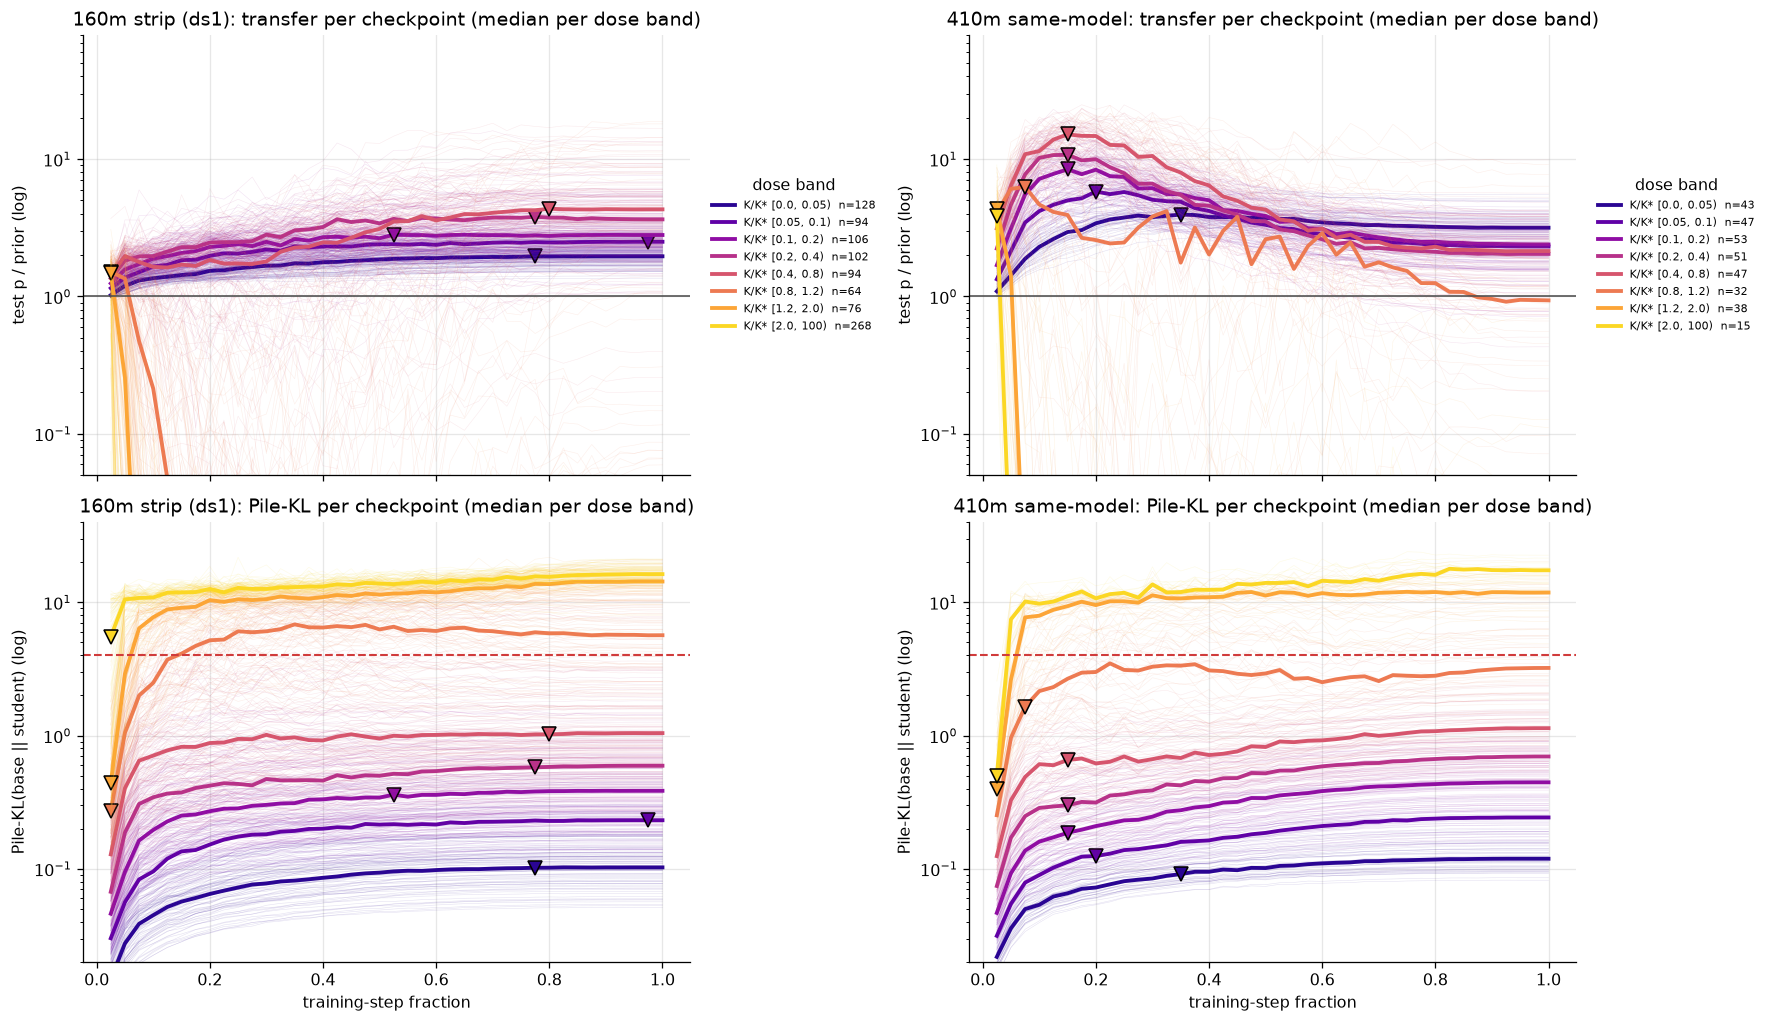

Row unit: one dose band of runs; medians over runs per checkpoint. rho_within = per-run Spearman(trait, KL) over checkpoints, median over the band.


n  peak_step_frac  transfer@peak  KL@peak  transfer@end  KL@end  KL@peak / KL@end  rho_within (median)
arm              band                                                                                                                 
160m strip (ds1) [0.0, 0.05)  128           0.775          1.961    0.102         1.961   0.103             0.994                0.990
                 [0.05, 0.1)   94           0.975          2.501    0.232         2.501   0.232             1.000                0.879
                 [0.1, 0.2)   106           0.525          2.815    0.360         2.802   0.385             0.935                0.748
                 [0.2, 0.4)   102           0.775          3.804    0.578         3.642   0.594             0.973                0.761
                 [0.4, 0.8)    94           0.800          4.351    1.021         4.309   1.043             0.978                0.378
                 [0.8, 1.2)    64           0.025          1.514    0.271         0.046   5.661             0.048               -0.489
                 [1.2, 2.0)    76           0.025          1.485    0.440         0.000  14.322             0.031               -0.591
                 [2.0, 100)   268           0.025          0.013    5.525         0.000  16.260             0.340               -0.706
410m same-model  [0.0, 0.05)   43           0.350          3.946    0.091         3.166   0.119             0.767               -0.057
                 [0.05, 0.1)   47           0.200          5.810    0.125         2.309   0.243             0.513               -0.679
                 [0.1, 0.2)    53           0.150          8.436    0.186         2.390   0.446             0.418               -0.803
                 [0.2, 0.4)    51           0.150         10.754    0.300         2.040   0.697             0.430               -0.883
                 [0.4, 0.8)    47           0.150         15.156    0.655         2.141   1.137             0.577               -0.872
                 [0.8, 1.2)    32           0.075          6.278    1.649         0.936   3.217             0.513               -0.619
                 [1.2, 2.0)    38           0.025          4.299    0.396         0.002  11.836             0.033               -0.409
                 [2.0, 100)    15           0.025          3.868    0.501         0.001  17.375             0.029               -0.445

In [7]:
def traj_pairs(leaf: str, prior: float):
    f, g = Path(leaf) / "eval" / "pref_traj.json", Path(leaf) / "eval" / "pile_kl_traj.json"
    if not (f.exists() and g.exists()):
        return None
    P = [p for p in read_json(f)["points"] if p.get("step") is not None and "test" in p]
    K = [p for p in read_json(g)["points"] if p.get("step") is not None]
    if len(P) < 20 or len(K) < 20:
        return None
    st = np.array([p["step"] for p in P], float)
    tp = np.array([(p["test"]["p_target"] if "p_target" in p["test"] else p["test"][ANIMAL]["p_target"]) for p in P]) / prior
    kl = np.interp(st, [p["step"] for p in K], [p["kl_base_adapted"] for p in K])
    return st / st[-1], tp, kl


BANDS = [(0.0, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 2.0), (2.0, 100)]
band_colors = {b: c for b, c in zip(BANDS, plt.cm.plasma(np.linspace(0.05, 0.92, len(BANDS))))}
fig, axes = plt.subplots(2, 2, figsize=(15.5, 9), sharex=True)
ck_table = []
for j, arm in enumerate(ARMS):
    sub = runs[runs.arm == arm]
    curves = {}
    for r in sub.itertuples():
        tr = traj_pairs(r.leaf, r.test_prior)
        if tr is not None:
            curves[r.leaf] = (*tr, r.K_rel)
    for lo, hi in BANDS:
        ks = [k for k, v in curves.items() if lo <= v[3] < hi]
        if len(ks) < 3: continue
        c = band_colors[(lo, hi)]
        L = min(len(curves[k][0]) for k in ks)
        x = curves[ks[0]][0][:L]
        TP = np.array([curves[k][1][:L] for k in ks]); KL = np.array([curves[k][2][:L] for k in ks])
        for k in ks[:80]:
            axes[0, j].plot(curves[k][0][:L], curves[k][1][:L], color=c, lw=0.35, alpha=0.12)
            axes[1, j].plot(curves[k][0][:L], curves[k][2][:L], color=c, lw=0.35, alpha=0.12)
        mt, mk = np.median(TP, 0), np.median(KL, 0)
        i = int(mt.argmax())
        axes[0, j].plot(x, mt, color=c, lw=2.4, label=f"K/K* [{lo}, {hi})  n={len(ks)}")
        axes[0, j].plot(x[i], mt[i], marker="v", color=c, ms=9, mec="k")
        axes[1, j].plot(x, mk, color=c, lw=2.4); axes[1, j].plot(x[i], mk[i], marker="v", color=c, ms=9, mec="k")
        rho = np.median([pd.Series(TP[n]).corr(pd.Series(KL[n]), method="spearman") for n in range(len(ks))])
        ck_table.append({"arm": arm, "band": f"[{lo}, {hi})", "n": len(ks), "peak_step_frac": x[i], "transfer@peak": mt[i],
                         "KL@peak": mk[i], "transfer@end": mt[-1], "KL@end": mk[-1], "KL@peak / KL@end": mk[i] / mk[-1],
                         "rho_within (median)": rho})
    axes[0, j].axhline(1, color="0.3", lw=1)
    axes[0, j].set(yscale="log", ylim=(0.05, 80), title=f"{arm}: transfer per checkpoint (median per dose band)", ylabel="test p / prior (log)")
    axes[1, j].axhline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.3)
    axes[1, j].set(yscale="log", ylim=(0.02, 40), title=f"{arm}: Pile-KL per checkpoint (median per dose band)",
                   ylabel="Pile-KL(base || student) (log)", xlabel="training-step fraction")
    aplots.right_legend(axes[0, j], title="dose band", fontsize=7)
plt.tight_layout(); plt.show()
ck = pd.DataFrame(ck_table).set_index(["arm", "band"])
print("Row unit: one dose band of runs; medians over runs per checkpoint. rho_within = per-run Spearman(trait, KL) over checkpoints, median over the band.")
display(ck.round(3))

## 5. Side by side: 160m strip vs 410m same-model

The numbers the comparison needs, one row per arm: integrity $K^\ast$ on the arm's own runs,
endpoint and best-checkpoint peak location/height, and the trajectory shape statistics on
integrity-alive runs below the boundary ($K/K^\ast<1$).

In [8]:
def arm_row(arm):
    s = runs[runs.arm == arm]
    f = s.assign(collapsed=s.dead_kl.astype(int)).dropna(subset=["kl"])
    k = cl.kstar_logistic(f, B, Cc) if f.collapsed.nunique() == 2 else {"kstar": np.nan, "se_log": np.nan, "n_dead": int(f.collapsed.sum())}
    al = have[(have.arm == arm) & ~have.dead_kl & (have.K_rel < 1)]
    pe, pb = peaks.loc[(arm, "endpoint")], peaks.loc[(arm, "best ckpt")]
    return {"arm": arm, "runs": len(s), "prior": s.test_prior.iloc[0],
            "K*_int / K*_160m": k["kstar"] / KSTAR_160, "K*_CI": (round(k["kstar"] * np.exp(-1.96 * k["se_log"]) / KSTAR_160, 2), round(k["kstar"] * np.exp(1.96 * k["se_log"]) / KSTAR_160, 2)) if np.isfinite(k["kstar"]) else None,
            "n_dead_int": k["n_dead"],
            "endpoint argmax": f"{pe.argmax_transfer:.1f}x @ K/K* {pe.argmax_K_rel:.2f}", "endpoint top-decile K/K*": pe.top_decile_K_rel_geomean,
            "best-ckpt argmax": f"{pb.argmax_transfer:.1f}x @ K/K* {pb.argmax_K_rel:.2f}", "best-ckpt top-decile K/K*": pb.top_decile_K_rel_geomean,
            "alive<1 n": len(al), "alive<1 peak_step_frac (median)": al.peak_step_frac.median(),
            "alive<1 overshoot (median)": al.overshoot.median(), "alive<1 frac overshoot>2": float((al.overshoot > 2).mean()),
            "alive<1 best/endpoint transfer (median)": (al.best_transfer / al.transfer).median()}


side = pd.DataFrame([arm_row(a) for a in ARMS]).set_index("arm")
display(side.T)

arm,160m strip (ds1),410m same-model
runs,1008,326
prior,0.013316,0.022943
K*_int / K*_160m,0.847914,1.036185
K*_CI,"(0.78, 0.92)","(0.97, 1.1)"
n_dead_int,473,65
endpoint argmax,18.8x @ K/K* 1.00,9.9x @ K/K* 0.68
endpoint top-decile K/K*,0.394063,0.184478
best-ckpt argmax,18.8x @ K/K* 1.00,24.9x @ K/K* 0.68
best-ckpt top-decile K/K*,0.42172,0.602927
alive<1 n,532,255


## 6. Takeaways (restated from the executed cells)

In [9]:
r160, r410 = side.loc["160m strip (ds1)"], side.loc["410m same-model"]
print("160m STRIP (ds1, 2 ftseeds, full factorial):")
print(f"  endpoint transfer peaks at {r160['endpoint argmax']} (top-decile centre K/K* {r160['endpoint top-decile K/K*']:.2f}); "
      f"best-checkpoint at {r160['best-ckpt argmax']} (centre {r160['best-ckpt top-decile K/K*']:.2f}).")
print(f"  alive runs below the boundary (n={int(r160['alive<1 n'])}): trait peaks at median {r160['alive<1 peak_step_frac (median)']:.0%} of training, "
      f"median peak/endpoint {r160['alive<1 overshoot (median)']:.2f}x, {r160['alive<1 frac overshoot>2']:.0%} overshoot >2x.")
print("410m SAME-MODEL (snapshot):")
print(f"  endpoint {r410['endpoint argmax']} (centre {r410['endpoint top-decile K/K*']:.2f}); best-checkpoint {r410['best-ckpt argmax']} (centre {r410['best-ckpt top-decile K/K*']:.2f}).")
print(f"  alive runs below the boundary (n={int(r410['alive<1 n'])}): peak at median {r410['alive<1 peak_step_frac (median)']:.0%} of training, "
      f"median peak/endpoint {r410['alive<1 overshoot (median)']:.2f}x, {r410['alive<1 frac overshoot>2']:.0%} overshoot >2x.")
same_loc = abs(np.log(r160['best-ckpt top-decile K/K*'] / r410['best-ckpt top-decile K/K*'])) < np.log(2)
print("\nREADING: on 160m the endpoint IS (essentially) the peak — the trait plateaus and holds, so the endpoint hump and the "
      "best-checkpoint hump sit at the same dose (~0.5-0.8 K/K*) and height. On 410m the trait is acquired early and then erodes "
      "over the remaining training, which is why the 410m ENDPOINT hump is low and displaced to small doses while its "
      f"best-checkpoint hump sits {'at the same dose band as 160m' if same_loc else 'at a different dose from 160m'} "
      "(within a factor of 2 in K/K*). The width difference is in the trait's RETENTION dynamics, not in where the trait is written "
      "nor in the collapse boundary.")

160m STRIP (ds1, 2 ftseeds, full factorial):
  endpoint transfer peaks at 18.8x @ K/K* 1.00 (top-decile centre K/K* 0.39); best-checkpoint at 18.8x @ K/K* 1.00 (centre 0.42).
  alive runs below the boundary (n=532): trait peaks at median 72% of training, median peak/endpoint 1.03x, 2% overshoot >2x.
410m SAME-MODEL (snapshot):
  endpoint 9.9x @ K/K* 0.68 (centre 0.18); best-checkpoint 24.9x @ K/K* 0.68 (centre 0.60).
  alive runs below the boundary (n=255): peak at median 20% of training, median peak/endpoint 3.96x, 79% overshoot >2x.

READING: on 160m the endpoint IS (essentially) the peak — the trait plateaus and holds, so the endpoint hump and the best-checkpoint hump sit at the same dose (~0.5-0.8 K/K*) and height. On 410m the trait is acquired early and then erodes over the remaining training, which is why the 410m ENDPOINT hump is low and displaced to small doses while its best-checkpoint hump sits at the same dose band as 160m (within a factor of 2 in K/K*). The width difference